# CSCI E-89 — Homework 09, Problem 1
## Student: **Hussein Jawad**

### Problem statement
Starting with the code in `scipy_fft.ipynb` / `lec09_speech_analysis.ipynb`, determine and plot the **real**, **imaginary**
and **absolute** value of $F(k)$, the FFT of

$$f(x) = \frac{1}{a^2x^4 + b^2}, \qquad a = b = 2 .$$

Then describe and plot how $F(k)$ changes if
1. we change $a$ to **1** (keeping $b = 2$), and separately
2. we keep $a = 1$ but replace $x$ with $x - 2$.

The three versions of $F(k)$ are plotted one below the other to emphasize the differences.

### Approach
We reuse the recipe from `scipy_fft.ipynb`:

1. Sample the function on an evenly spaced grid with `np.linspace(..., endpoint=False)` (the FFT assumes a periodic signal).
2. Call `fft()` to get the transform and `fftfreq()` to get the frequency $k$ of every FFT bin.
3. Plot `np.real()`, `np.imag()` and `np.abs()` of the (complex) result.

Two small additions are needed because, unlike the audio signal in the tutorial, our function is centered at $x = 0$
and we want a numerical approximation of the continuous Fourier transform
$F(k) = \int_{-\infty}^{\infty} f(x)\,e^{-2\pi i k x}\,dx$:

* `ifftshift()` moves the sample at $x = 0$ to index 0 before the FFT, so phases are measured from $x = 0$
  (otherwise the result would pick up an artificial phase factor from the start of the window at $x = -L$).
* Multiplying by the sample spacing `dx` turns the FFT sum into an approximation of the integral.
* `fftshift()` reorders the output from negative to positive $k$ for plotting.

### Running in Google Colab
This notebook runs as-is in Google Colab: it only needs `numpy`, `scipy` and `matplotlib`, which Colab already
has installed, and it reads no data files. Use **Runtime → Run all**.

### Step 1 — Imports

In [1]:
import numpy as np                                   # numerical arrays and math functions
from matplotlib import pyplot as plt                 # plotting
from scipy.fft import fft, fftfreq, fftshift, ifftshift  # FFT, bin frequencies, and helpers to re-center arrays

### Step 2 — Sampling grid
The window length `2L` and the number of samples `N` play the roles of `DURATION` and `SAMPLE_RATE * DURATION` in
`scipy_fft.ipynb`.
The function decays like $1/x^4$, so a window of $[-40, 40)$ is wide enough for $f$ (and its shifted version) to be
practically zero at the edges.

In [2]:
L = 40.0                                       # half-width of the x window: samples cover [-L, L)
N = 8192                                       # number of samples (a power of 2 keeps the FFT fast)
x = np.linspace(-L, L, N, endpoint=False)      # evenly spaced grid; endpoint=False because the FFT assumes periodicity
dx = x[1] - x[0]                               # sample spacing (the analogue of 1/SAMPLE_RATE)
print("dx =", dx)                              # show the spacing between samples
print("largest k the FFT can resolve (Nyquist) =", 1 / (2 * dx))  # Nyquist frequency = half the sampling rate

dx = 0.009765625
largest k the FFT can resolve (Nyquist) = 51.2


### Step 3 — Define $f(x)$ and the FFT helper
`f()` takes an optional `shift` so the same function also gives $f(x - 2)$.
`fourier()` wraps the `fft` / `fftfreq` calls from the tutorial.

In [3]:
def f(x, a, b, shift=0.0):                       # f(x - shift); shift = 0 gives the original f(x)
    return 1.0 / (a**2 * (x - shift)**4 + b**2)   # 1 / (a^2 (x - shift)^4 + b^2), evaluated on the whole x array

def fourier(y):                        # approximate continuous Fourier transform of samples y taken on grid x
    yf = fft(ifftshift(y)) * dx        # ifftshift puts x = 0 at index 0; * dx turns the FFT sum into an integral
    k = fftfreq(N, dx)                 # frequency k (cycles per unit of x) at the center of each FFT bin
    return fftshift(k), fftshift(yf)   # reorder both arrays from negative k to positive k for plotting

### Step 4 — Plot the three versions of $f(x)$
Before transforming, look at the functions themselves:
* **a = 2, b = 2** — the original function, peak $1/b^2 = 0.25$ at $x = 0$.
* **a = 1, b = 2** — same peak height (the peak $1/b^2$ does not depend on $a$) but **wider**.
* **a = 1, b = 2, x → x − 2** — identical shape to the previous one, just moved 2 units to the right.

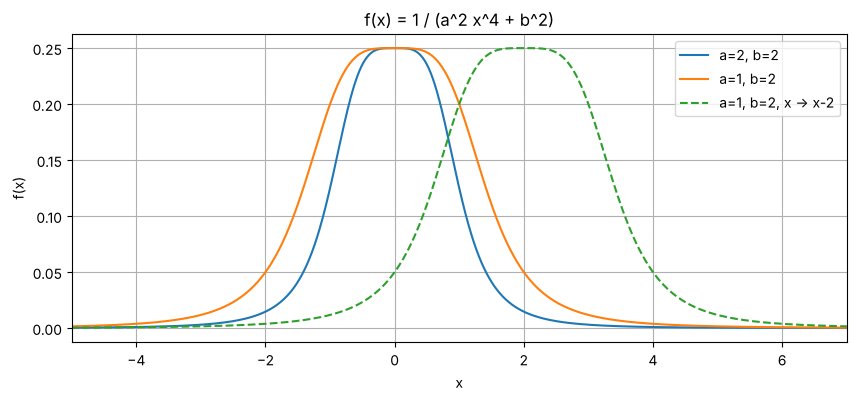

In [4]:
y1 = f(x, a=2, b=2)                    # version 1: a = b = 2
y2 = f(x, a=1, b=2)                    # version 2: a changed to 1
y3 = f(x, a=1, b=2, shift=2)           # version 3: a = 1 and x replaced by x - 2

plt.figure(figsize=(10, 4))                                # one wide figure for all three curves
plt.plot(x, y1, label="a=2, b=2")                          # original function
plt.plot(x, y2, label="a=1, b=2")                          # wider function
plt.plot(x, y3, "--", label="a=1, b=2, x -> x-2")          # same as y2 but shifted right by 2
plt.xlim(-5, 7)                                            # zoom in where the functions are non-negligible
plt.xlabel("x")                                            # horizontal axis label
plt.ylabel("f(x)")                                         # vertical axis label
plt.title("f(x) = 1 / (a^2 x^4 + b^2)")                    # plot title
plt.legend()                                               # show which curve is which
plt.grid(True)                                             # light grid for easier reading
plt.show()                                                 # render the figure

### Step 5 — FFT of $f(x)$ for $a = b = 2$: real, imaginary and absolute value

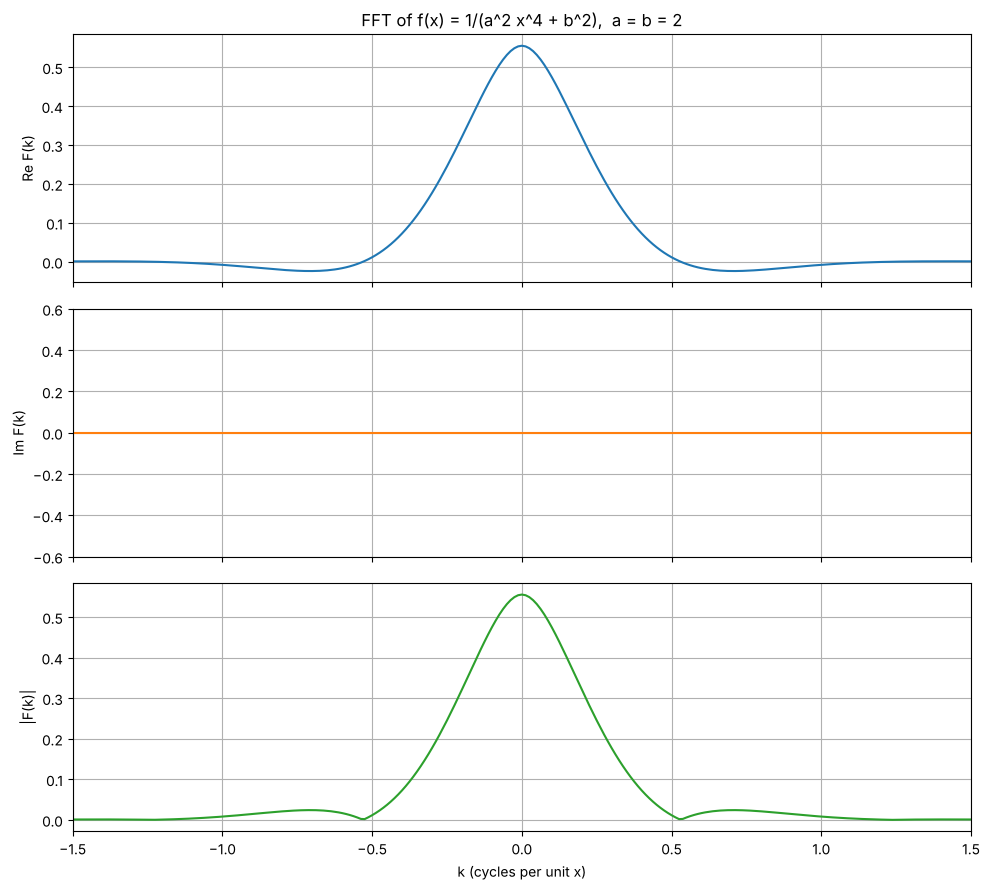

max |Im F(k)| = 6.288372600415926e-17


In [5]:
k, F1 = fourier(y1)                    # k axis and complex F(k) for a = b = 2

KMAX = 1.5                             # F(k) is negligible beyond |k| ~ 1.5, so zoom in there

fig, ax = plt.subplots(3, 1, figsize=(10, 9), sharex=True)   # three panels stacked vertically, shared k axis
ax[0].plot(k, np.real(F1), color="C0")                       # real part of F(k)
ax[0].set_ylabel("Re F(k)")                                  # label for the real-part panel
ax[0].set_title("FFT of f(x) = 1/(a^2 x^4 + b^2),  a = b = 2")  # figure title on the top panel
ax[1].plot(k, np.imag(F1), color="C1")                       # imaginary part of F(k)
ax[1].set_ylabel("Im F(k)")                                  # label for the imaginary-part panel
ax[1].set_ylim(-0.6, 0.6)                                    # same scale as Re F(k); autoscale would magnify 1e-17 round-off noise
ax[2].plot(k, np.abs(F1), color="C2")                        # magnitude |F(k)| = sqrt(Re^2 + Im^2)
ax[2].set_ylabel("|F(k)|")                                   # label for the magnitude panel
ax[2].set_xlabel("k (cycles per unit x)")                    # shared x label on the bottom panel
for axis in ax:                                              # apply common settings to every panel
    axis.set_xlim(-KMAX, KMAX)                               # same zoom on all panels
    axis.grid(True)                                          # light grid
plt.tight_layout()                                           # avoid overlapping labels
plt.show()                                                   # render the figure

print("max |Im F(k)| =", np.max(np.abs(np.imag(F1))))        # imaginary part should be ~0 (round-off only)

**Observations ($a = b = 2$):**
* $f(x)$ is **real and even**, so its Fourier transform is **real and even**: the imaginary part is zero up to
  floating-point round-off (~$10^{-17}$, printed above). It is drawn on the same scale as the real part, where it is a
  flat line at 0. If we let matplotlib autoscale that panel, it would magnify the round-off noise into meaningless
  spikes. Also $|F(k)| = \text{Re}\,F(k)$ wherever $F(k) \ge 0$.
* $F(k)$ is a smooth peak centered at $k = 0$ that dies out by $|k| \approx 1$. Like the square-wave example in
  `scipy_fft.ipynb`, the transform shows small side lobes: $\text{Re}\,F(k)$ dips slightly below zero (these appear as
  small bumps in $|F(k)|$), a damped oscillation that is typical of the transform of $1/(x^4 + c)$.
* $F(0) = \int f(x)\,dx$ is the area under $f(x)$.

### Step 6 — Sanity check: $F(0)$ equals the area under $f(x)$
Substituting $x = (b/a)^{1/2}u$ and using $\int_{-\infty}^{\infty}\frac{du}{u^4+1} = \frac{\pi}{\sqrt{2}}$ gives

$$F(0) = \int_{-\infty}^{\infty}\frac{dx}{a^2x^4+b^2} = \frac{\pi}{\sqrt{2}}\,a^{-1/2}\,b^{-3/2}.$$

In [6]:
def F0_exact(a, b):                                          # exact area under 1/(a^2 x^4 + b^2)
    return np.pi / np.sqrt(2) * a**-0.5 * b**-1.5            # (pi / sqrt 2) * a^(-1/2) * b^(-3/2), derived above

i0 = np.argmin(np.abs(k))                                    # index of the bin at k = 0
print("a=2, b=2:  FFT F(0) =", F1[i0].real, "  exact =", F0_exact(2, 2))  # compare numeric vs exact

a=2, b=2:  FFT F(0) = 0.5553577631034099   exact = 0.5553603672697959


The FFT value matches the exact integral, confirming the scaling by `dx` and the centering with `ifftshift`.

### Step 7 — Change $a$ to 1 (keep $b = 2$)

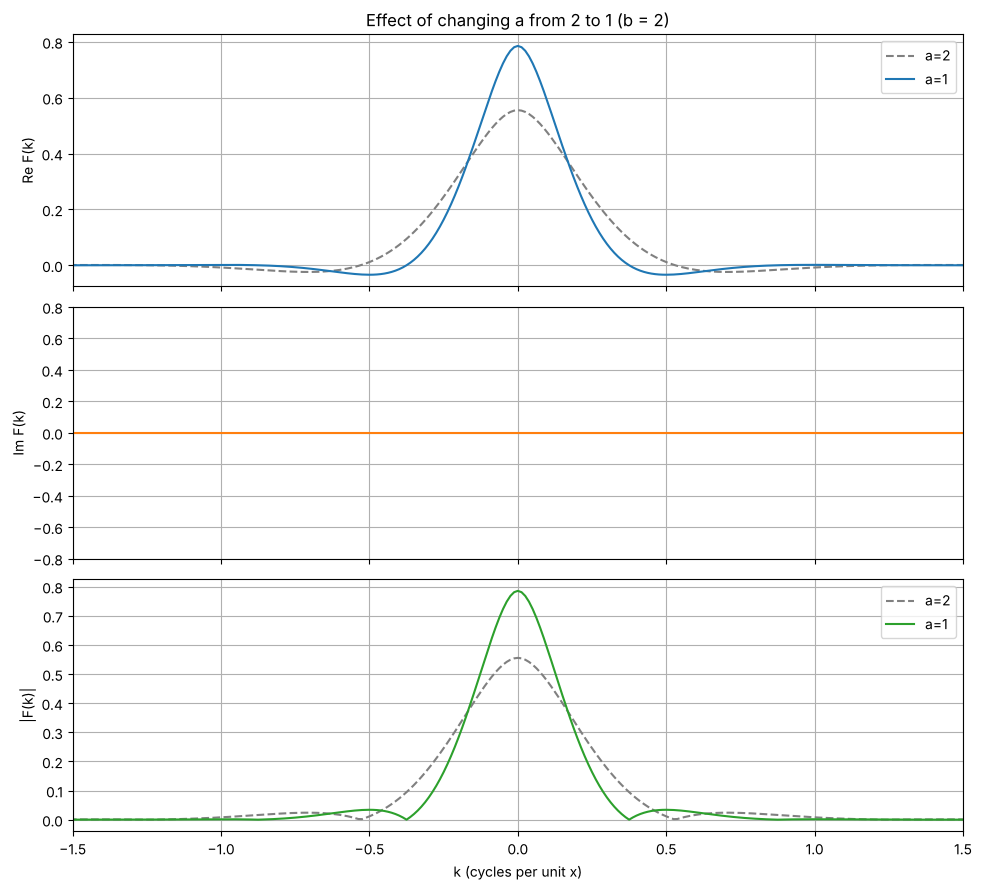

a=1, b=2:  FFT F(0) = 0.7853877467371362   exact = 0.7853981633974484
max |Im F(k)| = 8.409343100340694e-17
first zero of F(k):  a=2 -> 0.5305007613443261   a=1 -> 0.3749999803772963   ratio = 1.4146687709438726


In [7]:
k, F2 = fourier(y2)                                          # complex F(k) for a = 1, b = 2

fig, ax = plt.subplots(3, 1, figsize=(10, 9), sharex=True)   # three stacked panels, as before
ax[0].plot(k, np.real(F1), "--", color="gray", label="a=2")  # reference: real part for a = 2
ax[0].plot(k, np.real(F2), color="C0", label="a=1")          # real part for a = 1
ax[0].set_ylabel("Re F(k)")                                  # panel label
ax[0].set_title("Effect of changing a from 2 to 1 (b = 2)")  # figure title
ax[0].legend()                                               # identify the two curves
ax[1].plot(k, np.imag(F2), color="C1")                       # imaginary part for a = 1
ax[1].set_ylabel("Im F(k)")                                  # panel label
ax[1].set_ylim(-0.8, 0.8)                                    # same scale as Re F(k), so the ~0 imaginary part shows as a flat line
ax[2].plot(k, np.abs(F1), "--", color="gray", label="a=2")   # reference: magnitude for a = 2
ax[2].plot(k, np.abs(F2), color="C2", label="a=1")           # magnitude for a = 1
ax[2].set_ylabel("|F(k)|")                                   # panel label
ax[2].set_xlabel("k (cycles per unit x)")                    # shared x label
ax[2].legend()                                               # identify the two curves
for axis in ax:                                              # common settings for every panel
    axis.set_xlim(-KMAX, KMAX)                               # same zoom as before
    axis.grid(True)                                          # light grid
plt.tight_layout()                                           # avoid overlapping labels
plt.show()                                                   # render the figure

print("a=1, b=2:  FFT F(0) =", F2[i0].real, "  exact =", F0_exact(1, 2))  # area check for a = 1
print("max |Im F(k)| =", np.max(np.abs(np.imag(F2))))        # still ~0: f is still real and even

def first_zero(F):                                           # smallest k > 0 where Re F(k) changes sign
    kp, Fp = k[k > 0], np.real(F[k > 0])                     # keep only positive frequencies
    i = np.where(np.diff(np.sign(Fp)) != 0)[0][0]            # last bin before the first sign flip
    return kp[i] - Fp[i] * (kp[i+1] - kp[i]) / (Fp[i+1] - Fp[i])  # linear interpolation between the two bins

z1, z2 = first_zero(F1), first_zero(F2)                      # first zeros of F(k) for a = 2 and a = 1
print("first zero of F(k):  a=2 ->", z1, "  a=1 ->", z2, "  ratio =", z1 / z2)  # ratio should be ~sqrt(2) = 1.414

**Observations ($a = 1$):**
* Writing $a^2x^4 + b^2 = b^2\left[(x/s)^4 + 1\right]$ with width $s = (b/a)^{1/2}$ shows that $a$ only sets the
  **width** of $f(x)$: going from $a = 2$ to $a = 1$ makes $f(x)$ wider by a factor $\sqrt{2}$, while its peak
  $1/b^2$ stays the same.
* **Similarity Theorem** (time-scaling property, Lecture 09 slides). The slides write it with a scale factor
  called $a$; to avoid confusion with our parameter $a$, call that factor $c$: $\;g(cx) \to \frac{1}{|c|}G(k/c)$.
  Our function is $f(x) = g(\sqrt{a}\,x)$ with $g(u) = 1/(u^4 + b^2)$, so $c = \sqrt{a}$.
  Going from $a = 2$ to $a = 1$ changes $c$ from $\sqrt{2}$ to $1$. That stretches $f$ by $\sqrt{2}$ in $x$, so
  $F(k)$ is **compressed** by $\sqrt{2}$ in $k$ and its height grows by $\sqrt{2}$:
  * $F(0)$ grows from $\approx 0.555$ to $\approx 0.785$ ($=\pi/4$), a ratio of $\sqrt{2}$.
  * The first zero of $F(k)$ moves in from $|k| \approx 0.531$ to $\approx 0.375$, also a ratio of $\approx\sqrt{2}$
    (printed above).
  * This is the same effect seen with the narrow and wide square waves in `scipy_fft.ipynb`.
* $f$ is still real and even, so $F(k)$ is still **real** (imaginary part ≈ 0) and symmetric about $k = 0$.

### Step 8 — Keep $a = 1$ and replace $x$ with $x - 2$

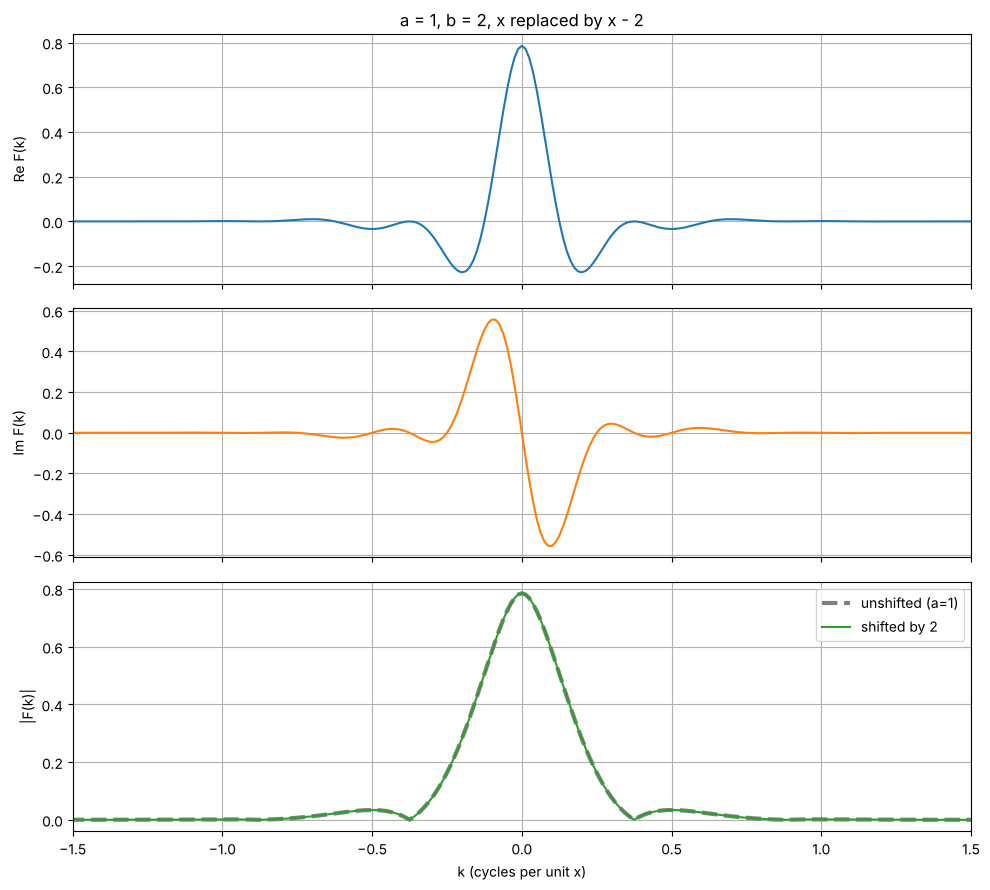

max | |F3| - |F2| | = 1.5800320496417442e-07
max | F3 - F2*exp(-4*pi*i*k) | = 1.5800320496417442e-07


In [8]:
k, F3 = fourier(y3)                                          # complex F(k) for a = 1, b = 2, shifted by 2

fig, ax = plt.subplots(3, 1, figsize=(10, 9), sharex=True)   # three stacked panels
ax[0].plot(k, np.real(F3), color="C0")                       # real part: now oscillates
ax[0].set_ylabel("Re F(k)")                                  # panel label
ax[0].set_title("a = 1, b = 2, x replaced by x - 2")         # figure title
ax[1].plot(k, np.imag(F3), color="C1")                       # imaginary part: no longer zero
ax[1].set_ylabel("Im F(k)")                                  # panel label
ax[2].plot(k, np.abs(F2), "--", color="gray", lw=3, label="unshifted (a=1)")  # reference magnitude
ax[2].plot(k, np.abs(F3), color="C2", label="shifted by 2")  # magnitude of the shifted version
ax[2].set_ylabel("|F(k)|")                                   # panel label
ax[2].set_xlabel("k (cycles per unit x)")                    # shared x label
ax[2].legend()                                               # identify the two curves
for axis in ax:                                              # common settings
    axis.set_xlim(-KMAX, KMAX)                               # same zoom as before
    axis.grid(True)                                          # light grid
plt.tight_layout()                                           # avoid overlapping labels
plt.show()                                                   # render the figure

print("max | |F3| - |F2| | =", np.max(np.abs(np.abs(F3) - np.abs(F2))))   # magnitudes should be identical
print("max | F3 - F2*exp(-4*pi*i*k) | =",                    # label for the next value
      np.max(np.abs(F3 - F2 * np.exp(-2j * np.pi * k * 2))))  # check the Time Shifting Property: F3 = F2 * e^{-2 pi i k 2}

**Observations ($x \to x - 2$):**
* By the **Time Shifting Property** (Lecture 09 slides), $f(x - x_0) \;\longrightarrow\; e^{-2\pi i k x_0}\,F(k)$.
  (The slides write this factor with angular frequency as $e^{\pm ikx_0}$; `scipy.fft` measures $k$ in cycles per
  unit of $x$, which brings in the $2\pi$ and the minus sign.) With $x_0 = 2$:
  $$F_{\text{shifted}}(k) = e^{-4\pi i k}\,F(k) \;\Rightarrow\;
  \text{Re} = F(k)\cos(4\pi k),\quad \text{Im} = -F(k)\sin(4\pi k).$$
* The **magnitude $|F(k)|$ is unchanged** — the shift does not change which frequencies are present or how strong they
  are (the two curves in the bottom panel lie on top of each other; the numeric difference is only ~$10^{-7}$, caused by cutting off the tails of $f$ at the edges of the finite window).
* The **real and imaginary parts now oscillate** with period $\Delta k = 1/x_0 = 0.5$ inside the $|F(k)|$ envelope.
  The imaginary part is no longer zero because $f(x - 2)$ is no longer even about $x = 0$.
* The real part stays even in $k$ and the imaginary part is odd in $k$, as required for the transform of any real function.

### Step 9 — The three versions of $F(k)$ one below the other
Each panel shows Re $F(k)$, Im $F(k)$ and $|F(k)|$ with identical axes so the differences are easy to see.

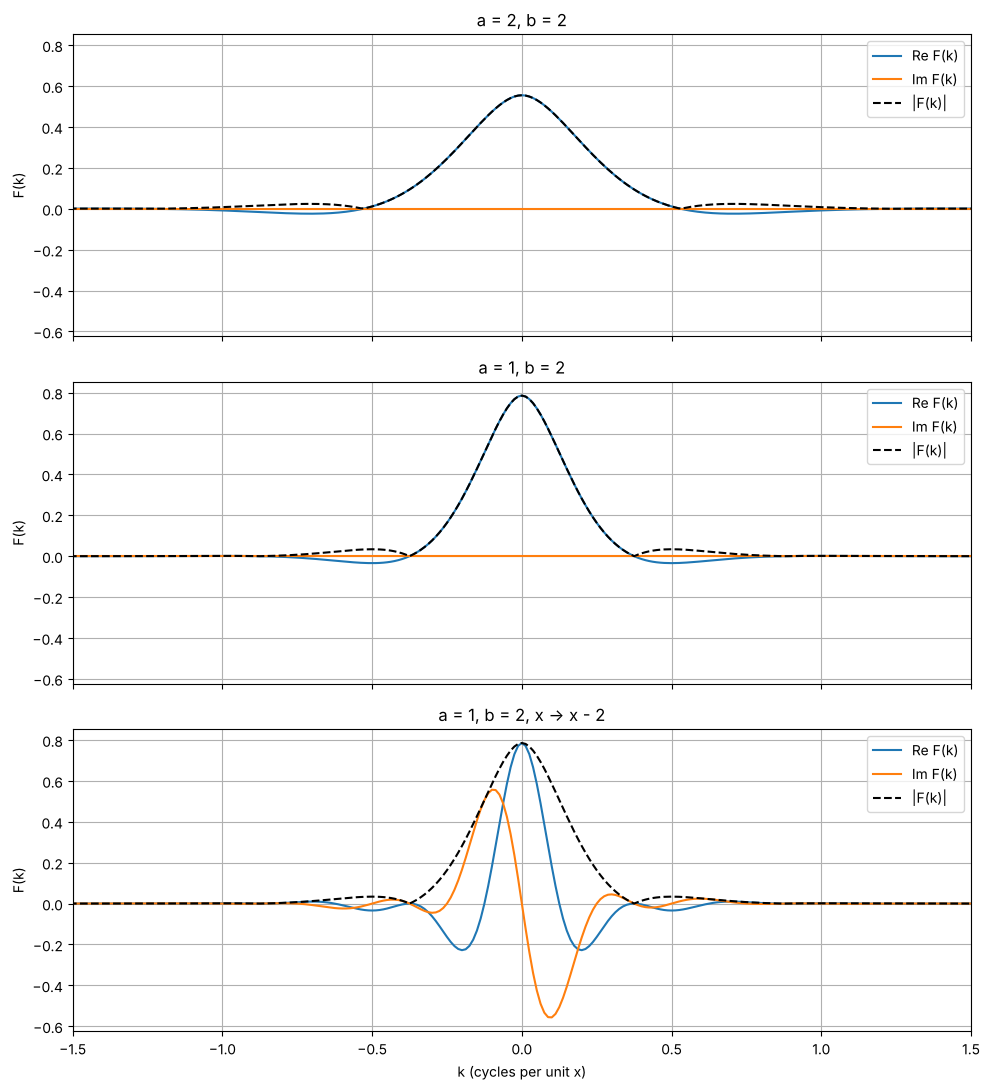

In [9]:
versions = [(F1, "a = 2, b = 2"),                            # version 1: original
            (F2, "a = 1, b = 2"),                            # version 2: a changed to 1
            (F3, "a = 1, b = 2, x -> x - 2")]                # version 3: a = 1 and shifted by 2

fig, ax = plt.subplots(3, 1, figsize=(10, 11), sharex=True, sharey=True)  # stacked panels with identical axes
for i, (F, name) in enumerate(versions):                     # one panel per version
    ax[i].plot(k, np.real(F), label="Re F(k)")               # real part
    ax[i].plot(k, np.imag(F), label="Im F(k)")               # imaginary part
    ax[i].plot(k, np.abs(F), "k--", label="|F(k)|")          # magnitude (dashed black envelope)
    ax[i].set_title(name)                                    # which version this panel shows
    ax[i].set_ylabel("F(k)")                                 # vertical axis label
    ax[i].set_xlim(-KMAX, KMAX)                              # same zoom on every panel
    ax[i].grid(True)                                         # light grid
    ax[i].legend(loc="upper right")                          # legend in each panel
ax[2].set_xlabel("k (cycles per unit x)")                    # shared x label on the bottom panel
plt.tight_layout()                                           # avoid overlapping labels
plt.show()                                                   # render the figure

## Summary

| Version | $f(x)$ | Re $F(k)$ | Im $F(k)$ | $\lvert F(k)\rvert$ |
|---|---|---|---|---|
| $a=2,\ b=2$ | even, width $\propto (b/a)^{1/2}=1$ | smooth even peak, $F(0)\approx0.555$ | $0$ | same as Re where $F\ge0$ |
| $a=1,\ b=2$ | even, $\sqrt{2}$ times **wider**, same peak $0.25$ | peak **taller** ($F(0)=\pi/4\approx0.785$) and $\sqrt{2}$ times **narrower** | $0$ | taller, narrower |
| $a=1,\ b=2,\ x\to x-2$ | same shape as row 2, moved to $x=2$ | $F(k)\cos(4\pi k)$ — oscillates | $-F(k)\sin(4\pi k)$ — oscillates | **identical to row 2** |

* **Changing $a$** rescales $x$: a wider function in $x$ has a narrower, taller transform in $k$ (Similarity Theorem),
  just like the narrow vs. wide square-wave pulses in `scipy_fft.ipynb`.
* **Shifting $x$** changes only the **phase** of $F(k)$ (Time Shifting Property): the energy at each frequency, $|F(k)|$,
  is unchanged, but the real and imaginary parts trade places periodically with period $1/2$ in $k$.